# EDA : Traitement initial des données 


In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
df = pd.read_csv("supermarket_sales_forecasting.csv")

print(df.shape)
df.head()

(5500, 16)


,Date,Store_ID,Store_Type,Store_Size,City,Promo,Holiday,School_Holiday,Weekend,Temperature,Rainfall,Fuel_Price,Inflation_Rate,Economic_Index,Competitor_Distance,Sales
0,2023-01-01,S003,B,3500,Parakou,0,0,0,1,27.2,17.2,694.03,4.85,91.4,4.5,11902.52
1,2023-01-01,S010,B,3300,Kandi,0,0,1,1,26.4,18.2,714.18,8.09,96.4,8.0,10822.53
2,2023-01-01,S003,B,3500,Parakou,0,0,0,1,27.9,18.6,669.26,7.71,101.4,4.5,10713.21
3,2023-01-01,S010,B,3300,Kandi,0,0,0,1,28.6,6.3,668.46,6.89,108.2,8.0,10925.09
4,2023-01-01,S008,A,4700,Ouidah,0,0,1,1,28.1,30.5,659.87,7.70,94.3,2.8,13415.18


In [36]:
#les information sur les variations 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 5500 non-null   object 
 1   Store_ID             5500 non-null   object 
 2   Store_Type           5500 non-null   object 
 3   Store_Size           5500 non-null   int64  
 4   City                 5500 non-null   object 
 5   Promo                5500 non-null   int64  
 6   Holiday              5500 non-null   int64  
 7   School_Holiday       5500 non-null   int64  
 8   Weekend              5500 non-null   int64  
 9   Temperature          5500 non-null   float64
 10  Rainfall             5500 non-null   float64
 11  Fuel_Price           5500 non-null   float64
 12  Inflation_Rate       5500 non-null   float64
 13  Economic_Index       5500 non-null   float64
 14  Competitor_Distance  5500 non-null   float64
 15  Sales                5500 non-null   f

In [4]:
# determination des valeurs manquantes
manque= df.isnull().sum().sort_values(ascending=False)
manque[manque > 0].count()
print(df.dtypes)
print(df.duplicated().sum())

Date                    object
Store_ID                object
Store_Type              object
Store_Size               int64
City                    object
Promo                    int64
Holiday                  int64
School_Holiday           int64
Weekend                  int64
Temperature            float64
Rainfall               float64
Fuel_Price             float64
Inflation_Rate         float64
Economic_Index         float64
Competitor_Distance    float64
Sales                  float64
dtype: object
0


In [5]:
df.describe()


,Store_Size,Promo,Holiday,School_Holiday,Weekend,Temperature,Rainfall,Fuel_Price,Inflation_Rate,Economic_Index,Competitor_Distance,Sales
count,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000
mean,3346.600000,0.302727,0.040000,0.150727,0.277273,29.728982,45.004345,680.132409,5.518195,99.957491,4.332709,9889.984880
std,866.554026,0.459480,0.195977,0.357815,0.447693,2.766481,33.631672,20.138989,1.745271,5.790438,2.275250,2588.551058
min,2100.000000,0.000000,0.000000,0.000000,0.000000,22.700000,0.000000,604.850000,2.500000,90.000000,1.200000,1507.070000
25%,2500.000000,0.000000,0.000000,0.000000,0.000000,27.700000,19.700000,666.600000,4.000000,95.000000,2.100000,8009.105000
50%,3300.000000,0.000000,0.000000,0.000000,0.000000,29.500000,33.900000,680.025000,5.520000,99.900000,4.500000,9807.080000
75%,4200.000000,1.000000,0.000000,0.000000,1.000000,31.600000,70.100000,693.585000,7.060000,105.000000,6.500000,11590.860000
max,4700.000000,1.000000,1.000000,1.000000,1.000000,39.200000,120.000000,760.310000,8.500000,110.000000,8.000000,18551.230000


### structure temporelle

In [6]:
#conversion des dates
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Store_ID", "Date"])
print(df["Date"])


16     2023-01-04
19     2023-01-04
28     2023-01-06
48     2023-01-08
50     2023-01-08
          ...    
5472   2025-12-26
5482   2025-12-28
5488   2025-12-29
5496   2025-12-31
5498   2025-12-31
Name: Date, Length: 5500, dtype: datetime64[ns]


In [7]:
#periode de datation
datemin=print(df["Date"].min())
datemax=print(df["Date"].max())

2023-01-01 00:00:00
2025-12-31 00:00:00


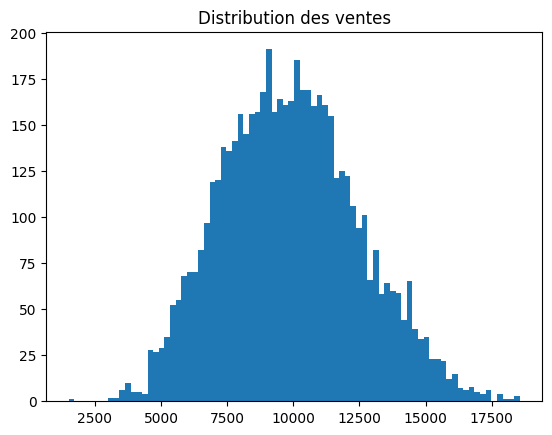

'COMMENTAIRE : La distribution des ventes est globalement centrée autour de 10 000 unités monétaires, avec des valeurs comprises entre environ 1 500 et 18 500.'

In [8]:
#analyse de distribution des ventes
plt.hist(df["Sales"], bins=80)
plt.title("Distribution des ventes")
plt.show()
'''COMMENTAIRE : La distribution des ventes est globalement centrée autour de 10 000 unités monétaires, avec des valeurs comprises entre environ 1 500 et 18 500.'''

Store_ID
S008    12646.334802
S001    12621.819415
S002    11630.687442
S003    10243.028649
S004     9937.881945
S007     9587.089203
S010     9160.916309
S005     8287.258750
S006     7870.891950
S009     7232.940036
Name: Sales, dtype: float64
Axes(0.125,0.11;0.775x0.77)


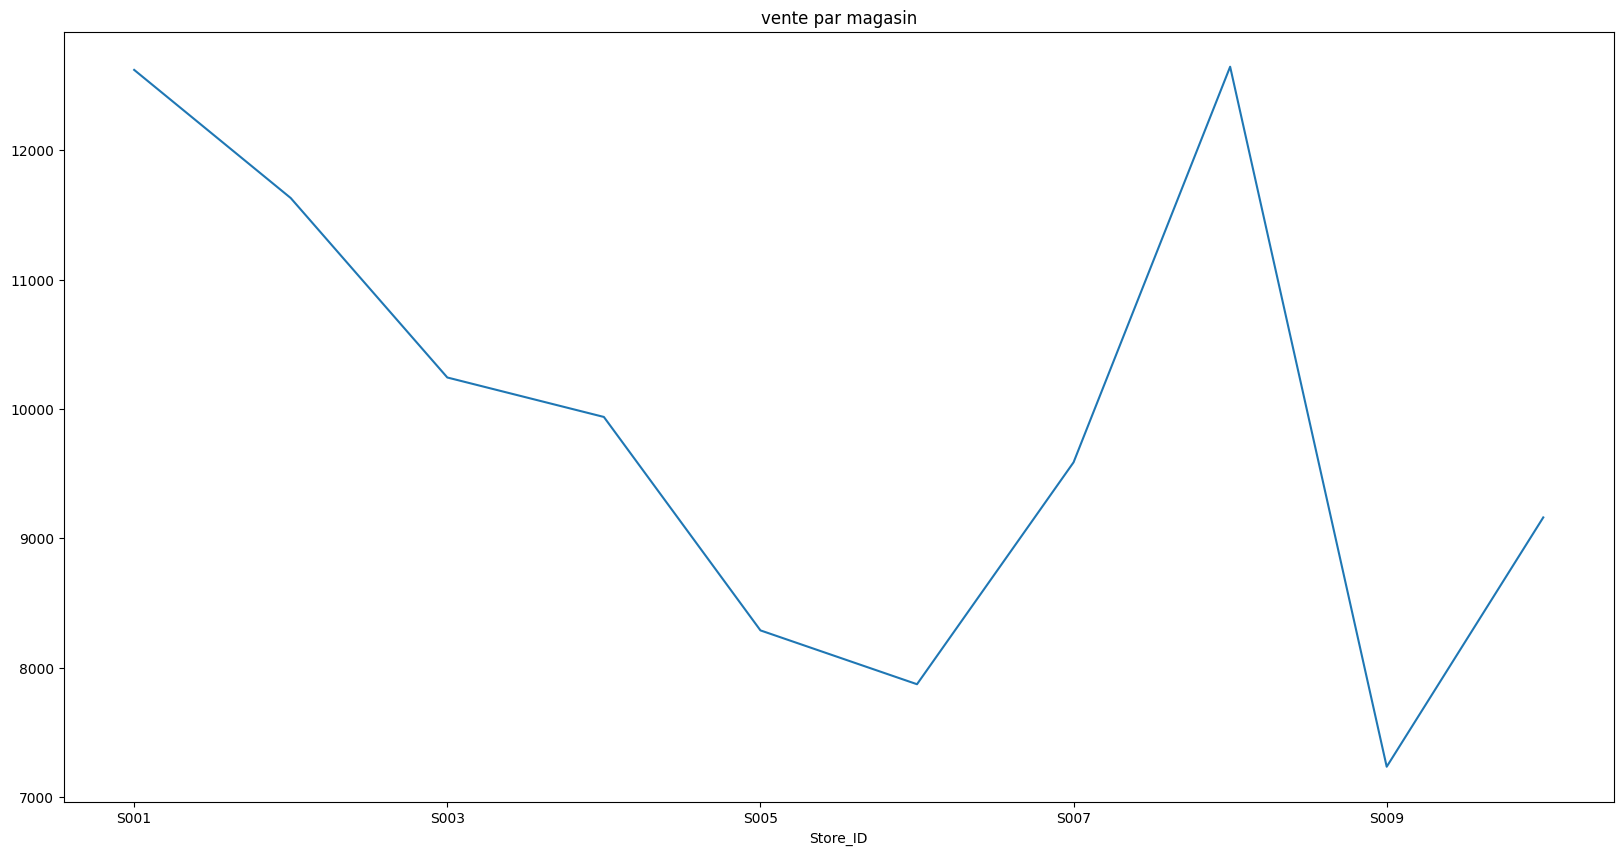

"COMMENTAIRE : Les ventes moyennes varient sensiblement d'un magasin à l'autre, ce qui révèle une hétérogénéité importante au sein du réseau. Le magasin S008 enregistre la moyenne de ventes la plus élevée (12 646), suivi de S001 (12 622) et S002 (11 631). À l'inverse, S009 présente la moyenne de ventes la plus faible (7 233), suivi de S006 (7 871) et S005 (8 287)."

In [9]:
#les ventes par magasin
impact_mag =df.groupby("Store_ID")["Sales"].mean().sort_values(ascending=False).head(5500)
print(impact_mag)
print(df.groupby("Store_ID")["Sales"].mean().plot(figsize=(20,10)))
plt.title("vente par magasin")
plt.show()
'''COMMENTAIRE : Les ventes moyennes varient sensiblement d'un magasin à l'autre, ce qui révèle une hétérogénéité importante au sein du réseau. Le magasin S008 enregistre la moyenne de ventes la plus élevée (12 646), suivi de S001 (12 622) et S002 (11 631). À l'inverse, S009 présente la moyenne de ventes la plus faible (7 233), suivi de S006 (7 871) et S005 (8 287).'''

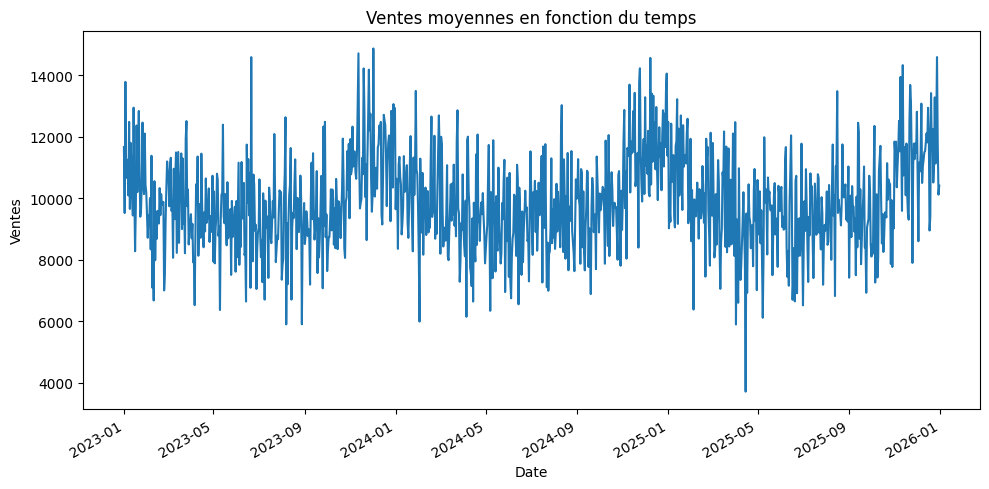

"INTERPRETATION : Le graphique montre que les ventes moyennes journalières oscillent de manière régulière sur les deux années, révélant une saisonnalité claire : des pics périodiques suivis de creux, probablement liés aux promotions, aux jours fériés et aux variations mensuelles simulées dans le dataset. Il n'y a pas de tendance haussière ou baissière sur le long terme — les ventes restent globalement stables autour d'une moyenne."

In [10]:
#impact de la date sur les ventes
df.groupby("Date")["Sales"].mean().plot(figsize=(10, 5))
plt.title("Ventes moyennes en fonction du temps")
plt.xlabel("Date")
plt.ylabel("Ventes")
plt.tight_layout()
plt.show()
'''INTERPRETATION : Le graphique montre que les ventes moyennes journalières oscillent de manière régulière sur les deux années, révélant une saisonnalité claire : des pics périodiques suivis de creux, probablement liés aux promotions, aux jours fériés et aux variations mensuelles simulées dans le dataset. Il n'y a pas de tendance haussière ou baissière sur le long terme — les ventes restent globalement stables autour d'une moyenne.'''

In [11]:
#impact de la var promotion sur les ventes
df.groupby("Promo")["Sales"].mean()

Promo
0     9120.024368
1    11663.437471
Name: Sales, dtype: float64

In [12]:
#impact de la var fériée  sur les ventes
df.groupby("Holiday")["Sales"].mean()


Holiday
0     9818.734960
1    11599.982955
Name: Sales, dtype: float64

In [13]:
#impact de la var weekend  sur les ventes
df.groupby("Weekend")["Sales"].mean()

Weekend
0     9554.148893
1    10765.360649
Name: Sales, dtype: float64

In [14]:
#impact de la var type du magasin  sur les ventes
df.groupby("Store_Type")["Sales"].mean().sort_values()

Store_Type
C     7803.569744
B     9718.173333
A    12309.392223
Name: Sales, dtype: float64

In [15]:
#impact de la var ville sur les ventes
df.groupby("City")["Sales"].mean().sort_values().head(10)

City
Djougou           7232.940036
Lokossa           7870.891950
Bohicon           8287.258750
Kandi             9160.916309
Natitingou        9587.089203
Abomey-Calavi     9937.881945
Parakou          10243.028649
Porto-Novo       11630.687442
Cotonou          12621.819415
Ouidah           12646.334802
Name: Sales, dtype: float64

## etude de correlation

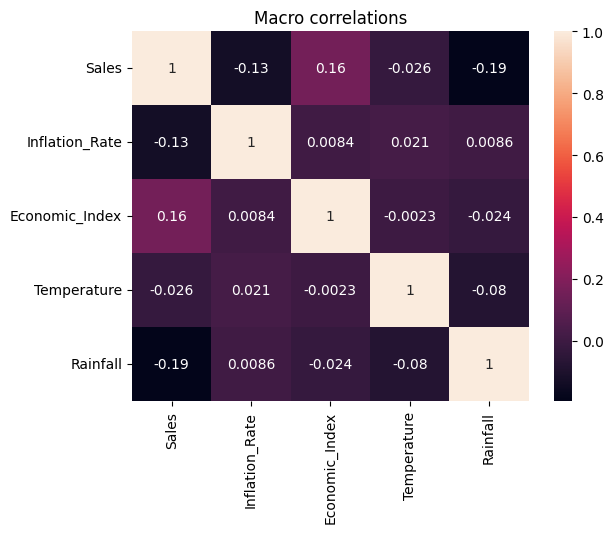

"INTERPRETATION :les variables macroéconomiques entretiennent des relations de forces variées avec les ventes. L'Economic_Index semble être la variable la plus corrélée positivement avec les Sales, ce qui est cohérent économiquement : un indice économique favorable stimule la consommation et donc les ventes. À l'inverse, l'Inflation_Rate présente une corrélation plus faible, voire légèrement négative, suggérant qu'une inflation élevée tend à éroder le pouvoir d'achat et freiner les ventes.\nVariables climatiques\nLa Temperature et le Rainfall affichent des corrélations modérées ou faibles avec les ventes, ce qui indique que les conditions météorologiques ont un impact limité sur la performance commerciale dans ce dataset. Ces variables sont également peu corrélées entre elles, ce qui est une bonne nouvelle pour la modélisation — elles apportent des informations distinctes et ne posent pas de problème de multicolinéarité.\nImplications pour la modélisation\nDans l'ensemble, aucune corré

In [16]:
#determination des correlations macroéconomiques
corr = df[["Sales","Inflation_Rate","Economic_Index","Temperature","Rainfall"]].corr()

sns.heatmap(corr, annot=True)
plt.title("Macro correlations")
plt.show()
'''INTERPRETATION :les variables macroéconomiques entretiennent des relations de forces variées avec les ventes. L'Economic_Index semble être la variable la plus corrélée positivement avec les Sales, ce qui est cohérent économiquement : un indice économique favorable stimule la consommation et donc les ventes. À l'inverse, l'Inflation_Rate présente une corrélation plus faible, voire légèrement négative, suggérant qu'une inflation élevée tend à éroder le pouvoir d'achat et freiner les ventes.
Variables climatiques
La Temperature et le Rainfall affichent des corrélations modérées ou faibles avec les ventes, ce qui indique que les conditions météorologiques ont un impact limité sur la performance commerciale dans ce dataset. Ces variables sont également peu corrélées entre elles, ce qui est une bonne nouvelle pour la modélisation — elles apportent des informations distinctes et ne posent pas de problème de multicolinéarité.
Implications pour la modélisation
Dans l'ensemble, aucune corrélation n'est suffisamment forte pour provoquer de la multicolinéarité critique entre les variables explicatives — ce qui est favorable pour les modèles de régression. Cependant, la faiblesse des corrélations macroéconomiques avec les ventes suggère que ces variables apporteront peu de pouvoir prédictif par rapport aux variables opérationnelles comme promo, store_type ou day_of_week, qui sont probablement bien plus déterminantes dans ce contexte.'''

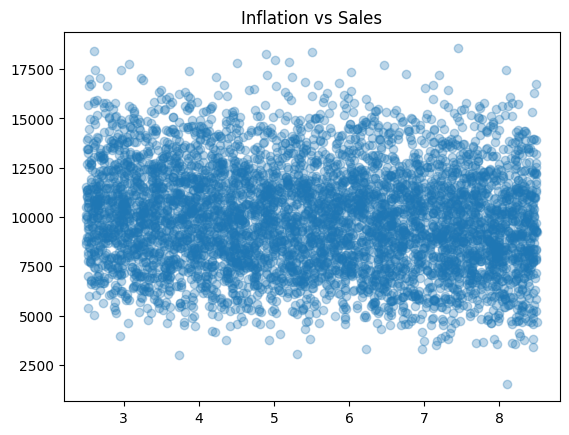

"COMMENTAIRE: on contact que les ventes et l'inflaction ne sont pas lineaire donc il y a absence de liaison entre l'inflation et les ventes"

In [17]:
#test non_lineaire entre l'infaction et les ventes
plt.scatter(df["Inflation_Rate"], df["Sales"], alpha=0.3)
plt.title("Inflation vs Sales")
plt.show()
'''COMMENTAIRE: on contact que les ventes et l'inflaction ne sont pas lineaire donc il y a absence de liaison entre l'inflation et les ventes'''


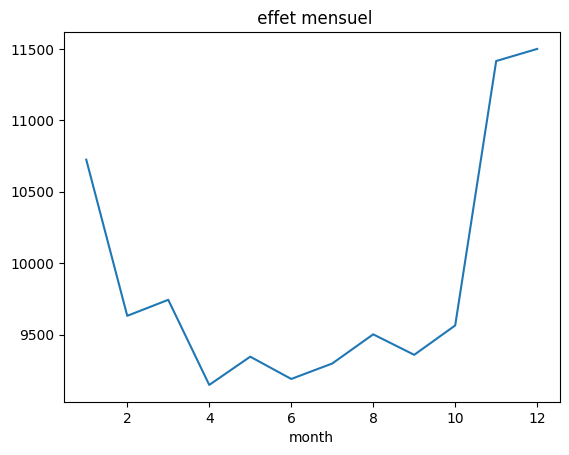

"INTERPRETATION : le graphique révèle une saisonnalité claire et régulière des ventes au fil des mois. La courbe n'est pas plate : elle monte et descend de façon rythmique, ce qui confirme que le mois de l'année est une variable explicative pertinente pour prédire les ventes."

In [18]:
#effet du mois
df["Date"] = pd.to_datetime(df["Date"])
df["month"] = df["Date"].dt.month
df["day_of_week"] = df["Date"].dt.dayofweek
df.groupby("month")["Sales"].mean().plot()
plt.title(" effet mensuel")
plt.show()
'''INTERPRETATION : le graphique révèle une saisonnalité claire et régulière des ventes au fil des mois. La courbe n'est pas plate : elle monte et descend de façon rythmique, ce qui confirme que le mois de l'année est une variable explicative pertinente pour prédire les ventes.'''

In [19]:
#classement des variables expliquants les ventes
numeric_df = df.select_dtypes(include=np.number)
corr_matrix = numeric_df.corr()
corr_matrix["Sales"].sort_values(ascending=False)

Sales                  1.000000
Store_Size             0.684423
Promo                  0.451468
Weekend                0.209481
day_of_week            0.170846
Economic_Index         0.155747
Holiday                0.134857
School_Holiday         0.113845
month                  0.111741
Temperature           -0.026399
Fuel_Price            -0.099078
Inflation_Rate        -0.129761
Rainfall              -0.194957
Competitor_Distance   -0.474550
Name: Sales, dtype: float64

In [20]:
#test des interactions

In [21]:
#interaction entre les var promotion et week-ends 
df.groupby(["Promo","Weekend"])["Sales"].mean()

Promo  Weekend
0      0           8803.282228
       1           9962.352939
1      0          11315.651751
       1          12529.620776
Name: Sales, dtype: float64

In [22]:
#interaction entre les var promotion et type de mag
df.groupby(["Promo","Store_Type"])["Sales"].mean()

Promo  Store_Type
0      A             11506.937121
       B              8951.773465
       C              7057.071641
1      A             14208.704193
       B             11410.917391
       C              9575.378494
Name: Sales, dtype: float64

In [23]:
#variance de structure
store_variance = df.groupby("Store_ID")["Sales"].var().sort_values()
store_variance.head()

Store_ID
S005    3.036318e+06
S010    3.114031e+06
S004    3.164750e+06
S006    3.310107e+06
S002    3.323440e+06
Name: Sales, dtype: float64

In [24]:
print(df.info())
print()
print(df.describe())
print()
print(df.groupby("Promo")["Sales"].mean())
print()
print(df.groupby("Holiday")["Sales"].mean())
print()
print(df.groupby("Weekend")["Sales"].mean())
print()
print(df.groupby("Store_Type")["Sales"].mean())
print()
numeric_df = df.select_dtypes(include="number")
print()
print(numeric_df.corr()["Sales"].sort_values(ascending=False))

<class 'pandas.core.frame.DataFrame'>
Index: 5500 entries, 16 to 5498
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 5500 non-null   datetime64[ns]
 1   Store_ID             5500 non-null   object        
 2   Store_Type           5500 non-null   object        
 3   Store_Size           5500 non-null   int64         
 4   City                 5500 non-null   object        
 5   Promo                5500 non-null   int64         
 6   Holiday              5500 non-null   int64         
 7   School_Holiday       5500 non-null   int64         
 8   Weekend              5500 non-null   int64         
 9   Temperature          5500 non-null   float64       
 10  Rainfall             5500 non-null   float64       
 11  Fuel_Price           5500 non-null   float64       
 12  Inflation_Rate       5500 non-null   float64       
 13  Economic_Index       5500 non-null   